In [130]:
# !pip install pymongo
# !pip install seaborn plotly matplotlib --quiet

In [131]:
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import numpy as np
from matplotlib.lines import Line2D 
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from scipy.stats import randint, uniform

In [ ]:
import pandas as pd
from pymongo import MongoClient

# 1) Ket noi MongoDB Atlas
client = MongoClient('mongodb+srv://<username>:<password>@cluster0.mongodb.net/')
db = client['ecom_data_lab']

# 2) Khai bao collection (chua load du lieu vao DataFrame)
products_col = db['fact_products']
shops_col = db['dim_shops']

# 3) Kiem tra ket noi nhanh
print('Da ket noi MongoDB thanh cong.')
print('Collections:', db.list_collection_names())

Da ket noi MongoDB thanh cong.
Collections: ['dim_shops', 'fact_products']


## Tổng quan dataset

In [133]:
# Kiem tra nhanh schema tu 1 ban ghi mau (khong load toan bo du lieu)
sample_product = products_col.find_one({}, {'_id': 0})
sample_shop = shops_col.find_one({}, {'_id': 0})

print('Cac cot fact_products:')
print(list(sample_product.keys()) if sample_product else 'Khong co du lieu')

print('\nCac cot dim_shops:')
print(list(sample_shop.keys()) if sample_shop else 'Khong co du lieu')

Cac cot fact_products:
['ID Sản phẩm', 'Tên sản phẩm', 'Danh mục', 'Giá', 'Giảm giá', 'Đã bán', 'Điểm đánh giá', 'Lượt đánh giá', 'Địa điểm', 'Tên shop', 'Seller ID']

Cac cot dim_shops:
['Seller ID', 'Loại cửa hàng', 'Followers', 'Đánh giá người bán', 'Danh mục chính', 'Số năm tham gia', 'Giao đúng hẹn', 'Tỷ lệ hủy đơn', 'Tỷ lệ phản hồi chat', 'Tên shop']


In [134]:
# Dem so luong san pham theo danh muc bang truy van toi thieu
category_col = 'Danh mục'

# Lay mau de tim ten cot danh muc
sample_product = products_col.find_one({}, {'_id': 0})
if sample_product is None:
    raise ValueError('fact_products khong co du lieu')

if category_col is None:
    raise ValueError(f'Khong tim thay cot danh muc. Cac cot hien co: {list(sample_product.keys())}')

cursor = products_col.find({}, {'_id': 0, category_col: 1})
df_category = pd.DataFrame(list(cursor))

product_count_by_category = (
    df_category.groupby(category_col)
    .size()
    .reset_index(name='So luong san pham')
    .sort_values('So luong san pham', ascending=False)
)

print(f'So danh muc: {product_count_by_category.shape[0]}')
display(product_count_by_category)

So danh muc: 9


,Danh mục,So luong san pham
5,Trang phục nam,2043
6,Trang phục nữ,1889
0,Chăm Sóc Da,669
2,Laptop,477
1,Dụng Cụ Làm Đẹp,433
7,Trang Điểm,431
8,Điện thoại di động,425
3,Máy tính bảng,387
4,Nước Hoa,267


## Mục tiêu 7: So sánh doanh thu giữa LazMall và Shop Thường ở cùng mức khuyến mãi, theo danh mục
- Chọn mức giảm giá 10-20% để so sánh.
- Lọc theo 4 danh mục: Trang phục nam, Trang phục nữ, Chăm Sóc Da, Laptop.
- Tính doanh thu trung vị/sản phẩm cho từng loại cửa hàng trong từng danh mục.
- Vẽ Bar Chart và Violin Plot để quan sát khác biệt phân phối doanh thu.

In [135]:
# Chuan bi du lieu rieng cho Muc tieu 7 (query-first)
selected_categories = ['Trang phục nam', 'Trang phục nữ', 'Chăm Sóc Da', 'Laptop']

pipeline_goal7 = [
    {
        '$match': {
            'Giảm giá': {'$gte': 0.1, '$lte': 0.2},
            'Danh mục': {'$in': selected_categories}
        }
    },
    {
        '$project': {
            '_id': 0,
            'Seller ID': 1,
            'Danh mục phân tích': '$Danh mục',
            'Giảm giá': {'$convert': {'input': '$Giảm giá', 'to': 'double', 'onError': 0, 'onNull': 0}},
            'Giá_num': {'$convert': {'input': '$Giá', 'to': 'double', 'onError': None, 'onNull': None}},
            'Đã_bán_num': {'$convert': {'input': '$Đã bán', 'to': 'double', 'onError': 0, 'onNull': 0}}
        }
    },
    {'$match': {'Giá_num': {'$ne': None}}},
    {'$set': {'revenue': {'$multiply': ['$Giá_num', '$Đã_bán_num']}}},
    {
        '$lookup': {
            'from': 'dim_shops',
            'let': {'sid': '$Seller ID'},
            'pipeline': [
                {'$match': {'$expr': {'$eq': ['$Seller ID', '$$sid']}}},
                {'$project': {'_id': 0, 'Loại cửa hàng': 1}}
            ],
            'as': 'shop'
        }
    },
    {'$unwind': '$shop'},
    {
        '$project': {
            '_id': 0,
            'Seller ID': 1,
            'Danh mục phân tích': 1,
            'Giảm giá': 1,
            'Loại cửa hàng': '$shop.Loại cửa hàng',
            'revenue': 1
        }
    }
]

df_discount = pd.DataFrame(list(products_col.aggregate(pipeline_goal7, allowDiskUse=True)))
if df_discount.empty:
    raise ValueError('Khong co du lieu sau khi loc cho Muc tieu 7')

print(f'So ban ghi Muc tieu 7: {df_discount.shape[0]}')
display(df_discount[['revenue', 'Loại cửa hàng', 'Giảm giá', 'Danh mục phân tích']].head())

So ban ghi Muc tieu 7: 524


,revenue,Loại cửa hàng,Giảm giá,Danh mục phân tích
0,183300.0,Shop Thường,0.14,Chăm Sóc Da
1,5395300.0,LazMall,0.18,Chăm Sóc Da
2,1106000.0,LazMall,0.18,Chăm Sóc Da
3,88160.0,Shop Thường,0.14,Chăm Sóc Da
4,20111.0,Shop Thường,0.16,Chăm Sóc Da


In [136]:
print('So ban ghi sau loc:', df_discount.shape[0])
print('Cac danh muc con lai:', df_discount['Danh mục phân tích'].unique())
display(df_discount[['revenue', 'Loại cửa hàng', 'Giảm giá', 'Danh mục phân tích']].head())

So ban ghi sau loc: 524
Cac danh muc con lai: <ArrowStringArray>
['Chăm Sóc Da', 'Laptop', 'Trang phục nam', 'Trang phục nữ']
Length: 4, dtype: str


,revenue,Loại cửa hàng,Giảm giá,Danh mục phân tích
0,183300.0,Shop Thường,0.14,Chăm Sóc Da
1,5395300.0,LazMall,0.18,Chăm Sóc Da
2,1106000.0,LazMall,0.18,Chăm Sóc Da
3,88160.0,Shop Thường,0.14,Chăm Sóc Da
4,20111.0,Shop Thường,0.16,Chăm Sóc Da


In [137]:
# Tính doanh thu trung vị/sản phẩm và số lượng sản phẩm theo danh mục + loại cửa hàng
avg_revenue = (
    df_discount.groupby(['Danh mục phân tích', 'Loại cửa hàng'])
    .agg(
        Doanh_thu_trung_vi=('revenue', 'median'),
        So_luong_san_pham=('revenue', 'size')
    )
    .reset_index()
    .sort_values(['Danh mục phân tích', 'Loại cửa hàng'])
)
print(avg_revenue)

  Danh mục phân tích Loại cửa hàng  Doanh_thu_trung_vi  So_luong_san_pham
0        Chăm Sóc Da       LazMall            481850.0                 16
1        Chăm Sóc Da   Shop Thường             13721.0                 66
2             Laptop       LazMall            194332.0                  6
3             Laptop   Shop Thường             86250.0                 42
4     Trang phục nam       LazMall             12036.0                 91
5     Trang phục nam   Shop Thường             14700.0                127
6      Trang phục nữ       LazMall              7434.0                  8
7      Trang phục nữ   Shop Thường              8888.4                168


### Mục tiêu phân tích

> Đánh giá mức chênh lệch hiệu quả bán hàng giữa LazMall và Shop Thường trong cùng dải khuyến mãi 10-20%, theo từng danh mục sản phẩm. Từ đó nhận diện nhóm ngành mà lợi thế thương hiệu (LazMall) thể hiện rõ nhất so với lợi thế giá của Shop Thường.

### Nguyên tắc SMART
> - S - Cụ thể: So sánh doanh thu giữa LazMall và Shop Thường, giới hạn nghiêm ngặt trong mức giảm giá 10-20% tại 4 danh mục cốt lõi.
> - M - Đo lường được: Định lượng rõ ràng qua chỉ số "Doanh thu trung vị trên mỗi sản phẩm" (nghìn VNĐ).
> - A - Khả thi: Hoàn toàn thực hiện được thông qua phép kết nối (lookup) dữ liệu sản phẩm và cửa hàng.
> - R - Liên quan: Trực tiếp trả lời bài toán chiến lược: "Ngành hàng nào thì doanh nghiệp nên đầu tư chi phí để lên chuẩn LazMall?".
> - T - Có thời hạn: Phản ánh bức tranh cạnh tranh tại thời điểm thu thập của tập dữ liệu hiện tại.

### Các trường dữ liệu (Metrics) được sử dụng

> - **Danh mục phân tích** *(Categorical/Phân loại)*: Trục phân tầng chính để so sánh theo từng nhóm sản phẩm.
> - **Loại cửa hàng** *(Categorical/Định danh)*: Biến đối chiếu giữa **LazMall** và **Shop Thường**.
> - **Giảm giá** *(Numerical/Liên tục)*: Điều kiện kiểm soát bối cảnh so sánh (giữ trong khoảng 10-20%).
> - **revenue** *(Numerical/Liên tục)*: Doanh thu trên từng sản phẩm, dùng để tính trung vị và phân phối.
> - **Doanh_thu_trung_vi** *(Numerical/Tổng hợp)*: Chỉ số trung tâm giúp so sánh mặt bằng hiệu quả bán hàng theo nhóm.

### Giải thích lý do phù hợp

> Cấu trúc phân tích này phù hợp vì đã **khống chế mức khuyến mãi** trước khi so sánh, giúp hạn chế nhiễu do giảm giá quá khác nhau giữa các shop.
> Trên nền điều kiện đó, việc kết hợp trục **Danh mục** và **Loại cửa hàng** cho phép kiểm định trực tiếp câu hỏi: lợi thế thương hiệu LazMall có nhất quán ở mọi ngành hàng hay chỉ nổi trội trong một số phân khúc cụ thể.
> Đồng thời, sử dụng cả chỉ số trung vị và phân phối doanh thu giúp tránh kết luận thiên lệch khi dữ liệu có ngoại lệ lớn, từ đó đưa ra nhận định thực tế hơn cho quyết định định vị cạnh tranh.

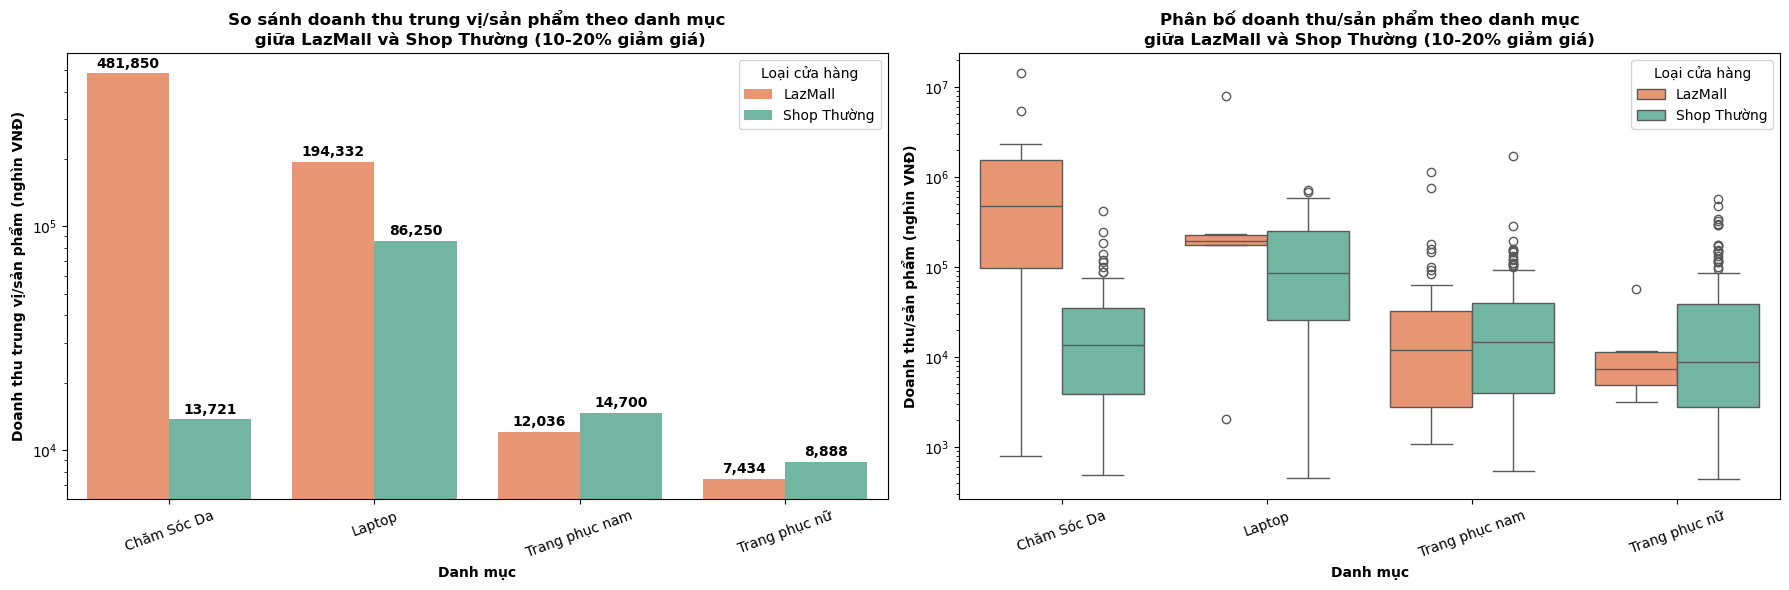

In [138]:
# Ve 2 bieu do chung 1 figure: ben trai la Bar Chart, ben phai la Box Plot
set2 = sns.color_palette('Set2', 2)
custom_palette = {'LazMall': set2[1], 'Shop Thường': set2[0]}
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Ben trai: Bar Chart
ax_left = sns.barplot(
    data=avg_revenue,
    x='Danh mục phân tích',
    y='Doanh_thu_trung_vi',
    hue='Loại cửa hàng',
    hue_order=['LazMall', 'Shop Thường'],
    palette=custom_palette,
    ax=axes[0]
)
ax_left.set_title('So sánh doanh thu trung vị/sản phẩm theo danh mục\n giữa LazMall và Shop Thường (10-20% giảm giá)', fontweight='bold')
ax_left.set_ylabel('Doanh thu trung vị/sản phẩm (nghìn VNĐ)', fontweight='bold')
ax_left.set_yscale('log')
ax_left.set_xlabel('Danh mục', fontweight='bold')
ax_left.tick_params(axis='x', rotation=20)

for container in ax_left.containers:
    labels = [f'{v:,.0f}' if v == v else '' for v in container.datavalues]
    ax_left.bar_label(container, labels=labels, padding=2, fontsize=10, fontweight='bold')

ax_left.legend(title='Loại cửa hàng')

# Ben phai: Box Plot
ax_right = sns.boxplot(
    data=df_discount,
    x='Danh mục phân tích',
    y='revenue',
    hue='Loại cửa hàng',
    hue_order=['LazMall', 'Shop Thường'],
    palette=custom_palette,
    ax=axes[1]
)
ax_right.set_title('Phân bố doanh thu/sản phẩm theo danh mục\ngiữa LazMall và Shop Thường (10-20% giảm giá)', fontweight='bold')
ax_right.set_ylabel('Doanh thu/sản phẩm (nghìn VNĐ)', fontweight='bold')
ax_right.set_yscale('log')
ax_right.set_xlabel('Danh mục', fontweight='bold')
ax_right.tick_params(axis='x', rotation=20)
ax_right.legend(title='Loại cửa hàng')

plt.tight_layout()
plt.show()

### Lý do chọn biểu đồ: 
>- Sử dụng kết hợp **Bar chart** và **Box plot** vì hai biểu đồ này bổ trợ trực tiếp cho mục tiêu so sánh hiệu quả bán hàng giữa LazMall và Shop Thường trong cùng dải khuyến mãi 10-20%. 
>- Bar chart giúp nhìn nhanh mức doanh thu trung vị theo từng danh mục và theo từng loại cửa hàng, phù hợp khi cần đối chiếu mặt bằng kết quả. 
>- Box plot bổ sung thông tin về độ phân tán, khoảng tứ phân vị và các điểm ngoại lệ, nhờ đó tránh kết luận sai khi chỉ nhìn vào giá trị trung tâm.
>
### Nhận xét từ biểu đồ: 
>- Dữ liệu cho thấy mức chênh doanh thu giữa LazMall và Shop Thường không cố định cho mọi danh mục mà thay đổi theo từng nhóm sản phẩm. Ở danh mục **Chăm Sóc Da** và **Laptop**, trung vị của LazMall vượt trội với Shop thường; ở danh mục **Trang phục nam/nữ** trung vị của hai nhóm gần nhau hơn nhưnvà Shop thường có phần nhỉnh hơn. 
>- Đồng thời, box plot cho thấy phân phối doanh thu bị lệch và xuất hiện nhiều outlier, nghĩa là hiệu quả bán hàng giữa các shop trong cùng một loại cửa hàng vẫn rất khác nhau. Điều này phản ánh tác động của nhiều yếu tố nền như tệp khách hàng, định vị sản phẩm và uy tín shop.
>
### Kết luận: 
>- Dữ liệu cho thấy nhãn LazMall không đảm bảo doanh thu cao cho mọi ngành hàng (ở mức giảm 10-20%). Với sản phẩm giá trị cao hoặc sức khỏe (Laptop, Chăm sóc da), LazMall áp đảo hoàn toàn. Ngược lại, ở ngành thời trang, Shop Thường cạnh tranh ngang ngửa.
>- Bên cạnh đó, độ phân tán dữ liệu rộng và nhiều điểm ngoại lệ (outliers) khẳng định: Năng lực vận hành riêng của từng shop mới là yếu tố tạo ra doanh thu đột phá.

### Tính chất SMART cho mục tiêu phân tích
- Specific: Nêu rõ đối tượng, phạm vi và câu hỏi phân tích.
- Measurable: Có chỉ số định lượng để đo và so sánh kết quả.
- Achievable: Khả thi với dữ liệu, công cụ và thời gian hiện có.
- Relevant: Gắn trực tiếp với vấn đề nghiên cứu và quyết định cần hỗ trợ.
- Time-bound: Xác định mốc thời gian hoặc giai đoạn dữ liệu cụ thể.

## Mục tiêu 8: Phân tích mức độ tác động của lượng Người theo dõi (Followers) đến doanh thu của gian hàng.
- Tính tổng doanh thu từng shop, phân nhóm theo lượng Followers.
- Vẽ Violin Chart và Bubble Chart.

In [139]:
# Muc tieu 8: Truy van du lieu
pipeline_goal8 = [
    {
        '$project': {
            '_id': 0,
            'Seller ID': 1,
            'Giá_num': {'$convert': {'input': '$Giá', 'to': 'double', 'onError': None, 'onNull': None}},
            'Đã_bán_num': {'$convert': {'input': '$Đã bán', 'to': 'double', 'onError': 0, 'onNull': 0}}
        }
    },
    {'$match': {'Giá_num': {'$ne': None}}},
    {'$set': {'revenue_line': {'$multiply': ['$Giá_num', '$Đã_bán_num']}}},
    {
        '$group': {
            '_id': '$Seller ID',
            'revenue': {'$sum': '$revenue_line'}
        }
    },
    {
        '$lookup': {
            'from': 'dim_shops',
            'let': {'sid': '$_id'},
            'pipeline': [
                {'$match': {'$expr': {'$eq': ['$Seller ID', '$$sid']}}},
                {
                    '$project': {
                        '_id': 0,
                        'Followers': {'$convert': {'input': '$Followers', 'to': 'double', 'onError': None, 'onNull': None}},
                        'Loại cửa hàng': 1,
                        'Tên shop': 1,
                        'Số năm tham gia': {'$convert': {'input': '$Số năm tham gia', 'to': 'double', 'onError': None, 'onNull': None}},
                        'Đánh giá người bán': {'$convert': {'input': '$Đánh giá người bán', 'to': 'double', 'onError': None, 'onNull': None}}
                    }
                }
            ],
            'as': 'shop'
        }
    },
    {'$unwind': '$shop'},
    {
        '$project': {
            '_id': 0,
            'Seller ID': '$_id',
            'revenue': 1,
            'Followers': '$shop.Followers',
            'Loại cửa hàng': '$shop.Loại cửa hàng',
            'Tên shop': '$shop.Tên shop',
            'Số năm tham gia': '$shop.Số năm tham gia',
            'Đánh giá người bán': '$shop.Đánh giá người bán'
        }
    }
]

shop_revenue = pd.DataFrame(list(products_col.aggregate(pipeline_goal8, allowDiskUse=True)))
if shop_revenue.empty:
    raise ValueError('Khong co du lieu sau khi truy van cho Muc tieu 8')

print(shop_revenue.head())

     revenue Seller ID  Followers Loại cửa hàng               Tên shop  \
0  18518.000     S1334     2170.0   Shop Thường              shop LoMo   
1  59816.535     S1353     3533.0       LazMall  JEEP SPIRIT 1941 ESTD   
2   3380.000     S0753       86.0   Shop Thường               lucky126   
3     74.500     S0721      104.0   Shop Thường              Liz 99999   
4  24502.500     S0242      285.0   Shop Thường      Shop mỹ phẩm TT 2   

   Số năm tham gia  Đánh giá người bán  
0              4.0                0.98  
1              4.0                0.95  
2              4.0                0.91  
3              5.0                0.93  
4              2.0                0.97  


In [140]:
# Phân nhóm Followers: <1k, 1k-10k, >10k
bins = [0, 1000, 10000, shop_revenue['Followers'].max()+1]
labels = ['<1k','1k-10k','>10k']
shop_revenue['followers_group'] = pd.cut(shop_revenue['Followers'], bins=bins, labels=labels, right=False)
print(shop_revenue[['Followers','followers_group']].head())

# Đếm số lượng shop theo từng nhóm Followers
shop_count_by_group = (
    shop_revenue['followers_group']
    .value_counts()
    .reindex(labels, fill_value=0)
    .rename_axis('followers_group')
    .reset_index(name='shop_count')
)
print(shop_count_by_group)

   Followers followers_group
0     2170.0          1k-10k
1     3533.0          1k-10k
2       86.0             <1k
3      104.0             <1k
4      285.0             <1k
  followers_group  shop_count
0             <1k         854
1          1k-10k         605
2            >10k         288


In [141]:
mean_revenue_follower = shop_revenue.groupby('followers_group')['revenue'].mean().reset_index()
print("Doanh thu trung bình:")
print(mean_revenue_follower)
median_revenue_follower = shop_revenue.groupby('followers_group')['revenue'].median().reset_index()
print("Doanh thu trung vị:")
print(median_revenue_follower)

Doanh thu trung bình:
  followers_group       revenue
0             <1k  7.381878e+04
1          1k-10k  2.320550e+05
2            >10k  2.787784e+06
Doanh thu trung vị:
  followers_group      revenue
0             <1k    7115.0000
1          1k-10k   23379.5000
2            >10k  100542.7125


### Mục tiêu phân tích

> Xác định mức độ tác động của quy mô người theo dõi đến doanh thu gian hàng, đồng thời kiểm chứng liệu xu hướng này có khác biệt theo loại cửa hàng (LazMall và Shop Thường) và theo mức độ thâm niên hoạt động.

### Nguyên tắc SMART
> - S - Cụ thể: Phân tích sự dịch chuyển mặt bằng doanh thu theo 3 phân khúc quy mô người theo dõi (<1k, 1k-10k, >10k).
> - M - Đo lường được: Trực quan hóa và đo lường thông qua phân phối khối Violin (log10) và đường xu hướng tương quan (Trendline).
> - A - Khả thi: Xử lý triệt để bằng kỹ thuật gom nhóm (groupby) doanh thu theo từng Seller ID.
> - R - Liên quan: Khẳng định giá trị tài chính của việc xây dựng cộng đồng, giúp shop định hình KPI tăng trưởng người theo dõi.
> - T - Có thời hạn: Đánh giá hiệu quả kinh doanh tích lũy tính đến vòng đời hiện tại của gian hàng.

### Các trường dữ liệu (Metrics) được sử dụng

> - **Followers** *(Numerical/Liên tục)*: Đại diện cho quy mô tệp khách hàng và mức độ nhận diện của gian hàng.
> - **followers_group** *(Categorical/Phân loại)*: Nhóm hóa followers thành `<1k`, `1k-10k`, `>10k` để so sánh phân phối doanh thu.
> - **revenue** *(Numerical/Liên tục)*: Tổng doanh thu theo từng seller, là biến kết quả chính.
> - **Loại cửa hàng** *(Categorical/Định danh)*: Trục phân tầng để đối chiếu hành vi giữa LazMall và Shop Thường.
> - **Số năm tham gia** *(Numerical/Liên tục)*: Biến phụ trợ thể hiện mức độ trưởng thành vận hành của gian hàng.

### Giải thích lý do phù hợp

> Mục tiêu này cần quan sát đồng thời **phân phối** và **tương quan**, nên bộ biến được chọn vừa bao quát mặt cắt nhóm (followers_group) vừa giữ được thông tin liên tục (Followers).
> Việc gộp doanh thu theo seller trước khi trực quan hóa giúp phản ánh đúng sức bán ở cấp gian hàng, tránh nhiễu do số lượng mẫu mã sản phẩm khác nhau giữa các shop.
> Bổ sung hai chiều **Loại cửa hàng** và **Số năm tham gia** giúp diễn giải sâu hơn: cùng quy mô followers nhưng hiệu quả doanh thu có thể khác nhau do uy tín nền tảng và năng lực vận hành.

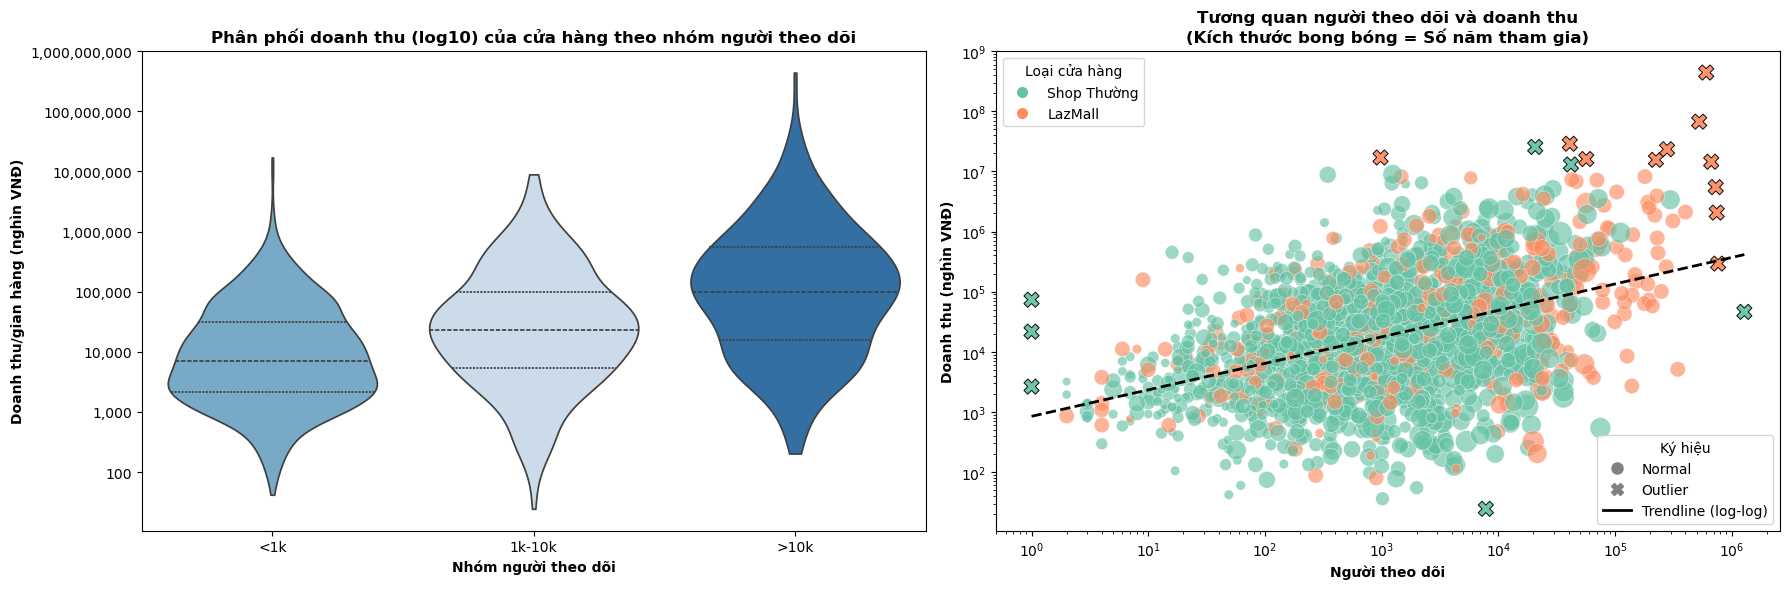

In [142]:
# Ve chung 1 figure: ben trai Violin, ben phai Bubble

# Du lieu cho violin
shop_revenue['revenue_log10'] = np.where(shop_revenue['revenue'] > 0, np.log10(shop_revenue['revenue']), np.nan)
violin_df = shop_revenue.dropna(subset=['revenue_log10']).copy()
follower_order = ['<1k', '1k-10k', '>10k']

# Du lieu cho bubble
plot_df = shop_revenue[[
    'Followers', 'revenue', 'Loại cửa hàng', 'Số năm tham gia', 'Đánh giá người bán',
    'followers_group'
 ]].dropna().copy()
plot_df = plot_df[(plot_df['Followers'] > 0) & (plot_df['revenue'] > 0)]
plot_df['bubble_size'] = plot_df['Số năm tham gia'].clip(lower=0) * 30 + 20

plot_df['log_followers'] = np.log10(plot_df['Followers'])
plot_df['log_revenue'] = np.log10(plot_df['revenue'])
q1_x, q3_x = plot_df['log_followers'].quantile([0.25, 0.75])
q1_y, q3_y = plot_df['log_revenue'].quantile([0.25, 0.75])
iqr_x = q3_x - q1_x
iqr_y = q3_y - q1_y
low_x, high_x = q1_x - 1.5 * iqr_x, q3_x + 1.5 * iqr_x
low_y, high_y = q1_y - 1.5 * iqr_y, q3_y + 1.5 * iqr_y
plot_df['is_outlier'] = (
    (plot_df['log_followers'] < low_x) | (plot_df['log_followers'] > high_x) |
    (plot_df['log_revenue'] < low_y) | (plot_df['log_revenue'] > high_y)
)

slope, intercept = np.polyfit(plot_df['log_followers'], plot_df['log_revenue'], 1)
x_line = np.geomspace(plot_df['Followers'].min(), plot_df['Followers'].max(), 200)
y_line = 10 ** (intercept + slope * np.log10(x_line))

shop_types = plot_df['Loại cửa hàng'].dropna().unique().tolist()
palette = dict(zip(shop_types, sns.color_palette('Set2', n_colors=len(shop_types))))

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Ben trai: Violin
ax_left = sns.violinplot(
    data=violin_df,
    x='followers_group',
    y='revenue_log10',
    order=follower_order,
    hue='followers_group',
    dodge=False,  
    palette='Blues',
    legend=False,
    cut=0,
    inner='quartile',
    ax=axes[0]
)

def format_revenue_from_log10(y, _):
    value = 10 ** y
    return f"{value:,.0f}"

ax_left.yaxis.set_major_formatter(FuncFormatter(format_revenue_from_log10))
ax_left.set_title('Phân phối doanh thu (log10) của cửa hàng theo nhóm người theo dõi', fontweight='bold')
ax_left.set_xlabel('Nhóm người theo dõi', fontweight='bold')
ax_left.set_ylabel('Doanh thu/gian hàng (nghìn VNĐ)', fontweight='bold')

# Ben phai: Bubble
sns.scatterplot(
    data=plot_df[~plot_df['is_outlier']],
    x='Followers',
    y='revenue',
    hue='Loại cửa hàng',
    size='bubble_size',
    sizes=(30, 300),
    palette=palette,
    alpha=0.65,
    edgecolor='white',
    linewidth=0.4,
    legend=False,
    ax=axes[1]
)
sns.scatterplot(
    data=plot_df[plot_df['is_outlier']],
    x='Followers',
    y='revenue',
    hue='Loại cửa hàng',
    palette=palette,
    marker='X',
    s=120,
    edgecolor='black',
    linewidth=0.7,
    alpha=0.95,
    legend=False,
    ax=axes[1]
)
axes[1].plot(x_line, y_line, color='black', linestyle='--', linewidth=2, label='Trendline (log-log)')
axes[1].set_xscale('log')
axes[1].set_yscale('log')
axes[1].set_title('Tương quan người theo dõi và doanh thu\n(Kích thước bong bóng = Số năm tham gia)', fontweight='bold')
axes[1].set_xlabel('Người theo dõi', fontweight='bold')
axes[1].set_ylabel('Doanh thu (nghìn VNĐ)', fontweight='bold')

shop_handles = [
    Line2D([0], [0], marker='o', color='w', label=shop,
           markerfacecolor=palette[shop], markeredgecolor='white', markersize=9)
    for shop in shop_types
]
legend_shop = axes[1].legend(handles=shop_handles, title='Loại cửa hàng', loc='upper left')
axes[1].add_artist(legend_shop)
symbol_handles = [
    Line2D([0], [0], marker='o', color='gray', label='Normal', linestyle='None', markersize=8),
    Line2D([0], [0], marker='X', color='gray', label='Outlier', linestyle='None', markersize=8),
    Line2D([0], [0], color='black', label='Trendline (log-log)', linewidth=2)
]
axes[1].legend(handles=symbol_handles, title='Ký hiệu', loc='lower right')

plt.tight_layout()
plt.show()

In [143]:
# Bang danh sach outlier: ten shop, loai shop, followers, doanh thu
outlier_df = shop_revenue.copy()

# Chon cot ten shop neu co, neu khong fallback bang Seller ID
shop_name_candidates = ['Tên shop', 'Tên cửa hàng', 'Shop Name', 'shop_name', 'shop_name_cleaned']
shop_name_col = next((c for c in shop_name_candidates if c in outlier_df.columns), None)
if shop_name_col is None:
    outlier_df['Tên shop'] = outlier_df['Seller ID'].astype(str)
    shop_name_col = 'Tên shop'

# Recompute outlier bang IQR trong khong gian log-log de dong nhat voi bieu do
tmp = outlier_df[(outlier_df['Followers'] > 0) & (outlier_df['revenue'] > 0)].copy()
tmp['log_followers'] = np.log10(tmp['Followers'])
tmp['log_revenue'] = np.log10(tmp['revenue'])

q1_x, q3_x = tmp['log_followers'].quantile([0.25, 0.75])
q1_y, q3_y = tmp['log_revenue'].quantile([0.25, 0.75])
iqr_x = q3_x - q1_x
iqr_y = q3_y - q1_y

low_x, high_x = q1_x - 1.5 * iqr_x, q3_x + 1.5 * iqr_x
low_y, high_y = q1_y - 1.5 * iqr_y, q3_y + 1.5 * iqr_y

tmp['is_outlier'] = (
    (tmp['log_followers'] < low_x) | (tmp['log_followers'] > high_x) |
    (tmp['log_revenue'] < low_y) | (tmp['log_revenue'] > high_y)
)

outlier_table = (
    tmp[tmp['is_outlier']][[shop_name_col, 'Loại cửa hàng', 'Followers', 'revenue']]
    .rename(columns={
        shop_name_col: 'Tên shop',
        'Loại cửa hàng': 'Loại shop',
        'revenue': 'Doanh thu (nghìn VNĐ)'
    })
    .sort_values('Doanh thu (nghìn VNĐ)', ascending=False)
    .reset_index(drop=True)
)

display_table = outlier_table.copy()
display_table['Followers'] = display_table['Followers'].map(lambda x: f"{x:,.0f}")
display_table['Doanh thu (nghìn VNĐ)'] = display_table['Doanh thu (nghìn VNĐ)'].map(lambda x: f"{x:,.0f}")

print(f"So outlier: {outlier_table.shape[0]}")
display(display_table)

So outlier: 18


,Tên shop,Loại shop,Followers,Doanh thu (nghìn VNĐ)
0,SAMSUNG Flagship Store,LazMall,"603,977","441,013,780"
1,Apple Flagship Store,LazMall,"525,574","67,275,895"
2,Xiaomi Official Store,LazMall,"40,947","28,890,100"
3,TB FASHION STORE,Shop Thường,"20,693","25,555,015"
4,Rohto Mentholatum,LazMall,"278,790","23,404,500"
5,Men Fashion Concept Store,LazMall,978,"17,058,548"
6,JessupBeauty,LazMall,"56,623","16,072,361"
7,Coolmate,LazMall,"224,021","15,608,509"
8,Kiehl's,LazMall,"666,891","14,483,100"
9,TAO Home Décor,Shop Thường,"41,912","13,071,007"


### Lý do chọn biểu đồ: 
>- Mục tiêu này cần đánh giá cả phân phối và tương quan, nên nhóm dùng **Violin plot** kết hợp **Bubble chart**. 
>- Violin plot ưu việt hơn Box plot ở chỗ vừa thể hiện được các mốc tứ phân vị (đường gạch ngang), vừa biểu diễn được mật độ phân phối (độ phình của biểu đồ) của doanh thu khi chia theo từng nhóm quy mô người theo dõi.
>- Bubble plot giúp đánh giá xu hướng tương quan liên tục giữa số người theo dõi và doanh thu (qua đường trendline), đồng thời cho phép lồng ghép thêm chiều dữ liệu về thâm niên hoạt động (kích thước bong bóng) và loại cửa hàng (màu sắc) để lý giải sâu hơn.
>
### Nhận xét từ biểu đồ: 
>- Biểu đồ Violin cho thấy sự dịch chuyển rõ rệt: Khi lượng người theo dõi tăng (từ <1k lên 1k-10k, và >10k), toàn bộ dải phân phối doanh thu và đường trung vị đều tịnh tiến lên các mốc cao hơn. Đặc biệt, nhóm **>10k** có mặt bằng doanh thu (phần đáy dải phân phối) vượt trội hoàn toàn so với nhóm **<1k**.
>- Biểu đồ phân tán xác nhận mối tương quan thuận mạnh mẽ (đường trendline hướng lên). Đồng thời, các gian hàng LazMall và gian hàng hoạt động lâu năm (bong bóng to) có xu hướng quy tụ ở khu vực góc trên bên phải (đông followers, doanh thu cao). Dù vậy, vẫn xuất hiện các ngoại lệ (dấu X) nơi một số Shop Thường có lượng followers thấp nhưng doanh thu đạt mức đột biến.
>
### Kết luận: 
>- Dữ liệu khẳng định lượng Người theo dõi có tác động tích cực và mạnh mẽ đến quy mô doanh thu. Việc xây dựng tệp followers (đặc biệt vượt mốc 10.000) giúp gian hàng thiết lập một mức doanh thu nền tảng (baseline) vững chắc hơn hẳn.
>- Tuy nhiên, sự thành công bền vững là tổng hòa của nhiều yếu tố uy tín (thâm niên hoạt động, nhãn LazMall) thay vì chỉ đếm số followers. Sự xuất hiện của các điểm ngoại lệ cũng chứng tỏ gian hàng nhỏ vẫn có thể bứt phá doanh thu cục bộ nhờ các chiến lược bán hàng ngắn hạn (chạy chiến dịch, độ viral sản phẩm).

### Tính chất SMART cho mục tiêu phân tích
- Specific: Nêu rõ đối tượng, phạm vi và câu hỏi phân tích.
- Measurable: Có chỉ số định lượng để đo và so sánh kết quả.
- Achievable: Khả thi với dữ liệu, công cụ và thời gian hiện có.
- Relevant: Gắn trực tiếp với vấn đề nghiên cứu và quyết định cần hỗ trợ.
- Time-bound: Xác định mốc thời gian hoặc giai đoạn dữ liệu cụ thể.

## Mục tiêu 11: Xây dựng mô hình Machine Learning dự đoán lượt bán
- Kết nối và truy vấn dữ liệu từ hai bảng `fact_products` và `dim_shops`, sau đó kiểm tra các cột bắt buộc trước khi huấn luyện.
- Làm sạch và chuẩn hóa dữ liệu: ép kiểu số, xử lý các cột tỷ lệ phần trăm, loại bỏ bản ghi thiếu/không hợp lệ của biến mục tiêu `Đã bán`.
- Xây dựng bộ đặc trưng gồm nhóm giá/khuyến mãi, danh mục, loại cửa hàng, mức độ uy tín shop và chỉ số vận hành.
- Chia dữ liệu train/test theo tỷ lệ 80/20 và áp dụng biến đổi `log1p` cho target để giảm lệch phân phối.
- Thiết kế pipeline tiền xử lý riêng cho mô hình tuyến tính và Random Forest (impute, scale, one-hot cho biến phân loại).
- Huấn luyện và so sánh 2 mô hình: Multiple Linear Regression và Random Forest; đồng thời tối ưu Random Forest bằng `RandomizedSearchCV`.
- Đánh giá mô hình bằng các chỉ số `R2` (log/original), `MAE`, `RMSE`, sau đó chọn mô hình tốt nhất theo hiệu năng thực tế.
- Trực quan hóa kết quả bằng 4 biểu đồ: Actual vs Predicted, Feature Importance, Residual Raw và Donut phân bố sai số tuyệt đối theo các ngưỡng `<20`, `20-100`, `>100`.
- Thực hiện thêm kịch bản dự báo chiến lược (+5% giảm giá) để ước lượng thay đổi tổng lượt bán toàn hệ thống và theo từng loại cửa hàng.

In [144]:
# Muc tieu 11: ML du doan luot ban voi du lieu truy van toi uu (query-first)

pipeline_goal11 = [
    {
        '$project': {
            '_id': 0,
            'Seller ID': 1,
            'Danh_muc': '$Danh mục',
            'Gia_num': {'$convert': {'input': '$Giá', 'to': 'double', 'onError': None, 'onNull': None}},
            'Giam_gia': {'$convert': {'input': '$Giảm giá', 'to': 'double', 'onError': 0, 'onNull': 0}},
            'Da_ban': {'$convert': {'input': '$Đã bán', 'to': 'double', 'onError': None, 'onNull': None}},
            'Diem_danh_gia': {'$convert': {'input': '$Điểm đánh giá', 'to': 'double', 'onError': None, 'onNull': None}},
            'Luot_danh_gia': {'$convert': {'input': '$Lượt đánh giá', 'to': 'double', 'onError': None, 'onNull': None}}
        }
    },
    {
        '$set': {
            'Giam_gia': {
                '$cond': [
                    {'$lt': ['$Giam_gia', 0]},
                    0,
                    {'$cond': [{'$gte': ['$Giam_gia', 1]}, 0.99, '$Giam_gia']}
                ]
            }
        }
    },
    {'$set': {'Gia_goc': {'$divide': ['$Gia_num', {'$subtract': [1, '$Giam_gia']}]}}},
    {
        '$lookup': {
            'from': 'dim_shops',
            'let': {'sid': '$Seller ID'},
            'pipeline': [
                {'$match': {'$expr': {'$eq': ['$Seller ID', '$$sid']}}},
                {
                    '$project': {
                        '_id': 0,
                        'Loai_cua_hang': '$Loại cửa hàng',
                        'Followers': {'$convert': {'input': '$Followers', 'to': 'double', 'onError': None, 'onNull': None}},
                        'Danh_gia_nguoi_ban': {'$convert': {'input': '$Đánh giá người bán', 'to': 'double', 'onError': None, 'onNull': None}},
                        'So_nam_tham_gia': {'$convert': {'input': '$Số năm tham gia', 'to': 'double', 'onError': None, 'onNull': None}},
                        'Ty_le_phan_hoi_chat_raw': {
                            '$convert': {
                                'input': {'$replaceAll': {'input': {'$toString': '$Tỷ lệ phản hồi chat'}, 'find': '%', 'replacement': ''}},
                                'to': 'double',
                                'onError': None,
                                'onNull': None
                            }
                        },
                        'Giao_dung_hen_raw': {
                            '$convert': {
                                'input': {'$replaceAll': {'input': {'$toString': '$Giao đúng hẹn'}, 'find': '%', 'replacement': ''}},
                                'to': 'double',
                                'onError': None,
                                'onNull': None
                            }
                        }
                    }
                }
            ],
            'as': 'shop'
        }
    },
    {'$unwind': '$shop'},
    {
        '$project': {
            '_id': 0,
            'Gia_goc': 1,
            'Giam_gia': 1,
            'Danh_muc': 1,
            'Diem_danh_gia': 1,
            'Luot_danh_gia': 1,
            'Loai_cua_hang': '$shop.Loai_cua_hang',
            'Followers': '$shop.Followers',
            'Danh_gia_nguoi_ban': '$shop.Danh_gia_nguoi_ban',
            'So_nam_tham_gia': '$shop.So_nam_tham_gia',
            'Ty_le_phan_hoi_chat': {
                '$cond': [
                    {'$gt': ['$shop.Ty_le_phan_hoi_chat_raw', 1]},
                    {'$divide': ['$shop.Ty_le_phan_hoi_chat_raw', 100]},
                    '$shop.Ty_le_phan_hoi_chat_raw'
                ]
            },
            'Giao_dung_hen': {
                '$cond': [
                    {'$gt': ['$shop.Giao_dung_hen_raw', 1]},
                    {'$divide': ['$shop.Giao_dung_hen_raw', 100]},
                    '$shop.Giao_dung_hen_raw'
                ]
            },
            'Da_ban': 1
        }
    },
    {
        '$match': {
            'Da_ban': {'$ne': None, '$gte': 0},
            'Gia_goc': {'$ne': None, '$gt': 0}
        }
    }
]

ml_df = pd.DataFrame(list(products_col.aggregate(pipeline_goal11, allowDiskUse=True)))
if ml_df.empty:
    raise ValueError('Khong co du lieu fact_products sau truy van cho Muc tieu 11')

# Chuan hoa bo sung de dam bao du lieu dau vao mo hinh on dinh
num_cols = [
    'Gia_goc', 'Giam_gia', 'Diem_danh_gia', 'Luot_danh_gia',
    'Followers', 'Danh_gia_nguoi_ban', 'So_nam_tham_gia',
    'Ty_le_phan_hoi_chat', 'Giao_dung_hen', 'Da_ban'
 ]
for c in num_cols:
    ml_df[c] = pd.to_numeric(ml_df[c], errors='coerce')
ml_df['Giam_gia'] = ml_df['Giam_gia'].clip(lower=0, upper=0.99)
ml_df['Ty_le_phan_hoi_chat'] = ml_df['Ty_le_phan_hoi_chat'].clip(lower=0, upper=1)
ml_df['Giao_dung_hen'] = ml_df['Giao_dung_hen'].clip(lower=0, upper=1)

feature_cols = [
    'Gia_goc',
    'Giam_gia',
    'Danh_muc',
    'Diem_danh_gia',
    'Loai_cua_hang',
    'Followers',
    'Danh_gia_nguoi_ban',
    'So_nam_tham_gia',
    'Ty_le_phan_hoi_chat',
    'Giao_dung_hen'
 ]

ml_df = ml_df[feature_cols + ['Da_ban']].copy()
ml_df = ml_df[ml_df['Da_ban'].notna()]
ml_df = ml_df[ml_df['Da_ban'] >= 0]
ml_df = ml_df[ml_df['Gia_goc'].isna() | (ml_df['Gia_goc'] > 0)]

X = ml_df[feature_cols]
y = ml_df['Da_ban']
y_log = np.log1p(y)

X_train, X_test, y_train, y_test, y_train_log, y_test_log = train_test_split(
    X, y, y_log, test_size=0.2, random_state=42
)

numeric_features = [
    'Gia_goc', 'Giam_gia', 'Diem_danh_gia',
    'Followers', 'Danh_gia_nguoi_ban', 'So_nam_tham_gia',
    'Ty_le_phan_hoi_chat', 'Giao_dung_hen'
 ]
categorical_features = ['Danh_muc', 'Loai_cua_hang']

numeric_linear = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
numeric_rf = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocess_linear = ColumnTransformer([
    ('num', numeric_linear, numeric_features),
    ('cat', categorical_pipeline, categorical_features)
])
preprocess_rf = ColumnTransformer([
    ('num', numeric_rf, numeric_features),
    ('cat', categorical_pipeline, categorical_features)
])

linear_model = Pipeline([
    ('preprocess', preprocess_linear),
    ('model', LinearRegression())
])

rf_pipeline = Pipeline([
    ('preprocess', preprocess_rf),
    ('model', RandomForestRegressor(random_state=42, n_jobs=-1))
])

# 3) Tune Random Forest de tang do chinh xac
param_dist = {
    'model__n_estimators': randint(300, 1200),
    'model__max_depth': randint(8, 28),
    'model__min_samples_split': randint(2, 20),
    'model__min_samples_leaf': randint(1, 10),
    'model__max_features': uniform(0.4, 0.6)
}

rf_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_dist,
    n_iter=20,
    scoring='r2',
    cv=5,
    random_state=42,
    n_jobs=-1
)

linear_model.fit(X_train, y_train_log)
rf_search.fit(X_train, y_train_log)

rf_model = rf_search.best_estimator_

pred_linear_log = linear_model.predict(X_test)
pred_rf_log = rf_model.predict(X_test)
pred_linear = np.expm1(pred_linear_log).clip(min=0)
pred_rf = np.expm1(pred_rf_log).clip(min=0)

metrics = pd.DataFrame([
    {
        'Model': 'Multiple Linear Regression (log target)',
        'R2_log': r2_score(y_test_log, pred_linear_log),
        'R2_original': r2_score(y_test, pred_linear),
        'MAE': mean_absolute_error(y_test, pred_linear),
        'RMSE': root_mean_squared_error(y_test, pred_linear)
    },
    {
        'Model': 'Random Forest Tuned (log target)',
        'R2_log': r2_score(y_test_log, pred_rf_log),
        'R2_original': r2_score(y_test, pred_rf),
        'MAE': mean_absolute_error(y_test, pred_rf),
        'RMSE': root_mean_squared_error(y_test, pred_rf)
    }
]).sort_values('R2_log', ascending=False).reset_index(drop=True)

best_model_name = metrics.loc[0, 'Model']
best_model = rf_model if 'Random Forest' in best_model_name else linear_model
best_pred_log = pred_rf_log if 'Random Forest' in best_model_name else pred_linear_log
best_pred = np.expm1(best_pred_log).clip(min=0)
best_r2_log = metrics.loc[0, 'R2_log']
best_r2_original = metrics.loc[0, 'R2_original']


### Mục tiêu phân tích

> Đánh giá năng lực dự báo lượt bán của mô hình Machine Learning và kiểm tra mức độ tin cậy thực tế thông qua sai số dự đoán. Đồng thời, xác định các đặc trưng ảnh hưởng mạnh nhất để phục vụ giải thích hành vi mua sắm theo góc nhìn dữ liệu.

### Nguyên tắc SMART
> - S - Cụ thể: Xây dựng mô hình Random Forest dự đoán lượt bán dựa trên 10 đặc trưng, đồng thời giả lập tác động khi giảm giá đồng loạt 5%.
> - M - Đo lường được: Đánh giá độ tin cậy của thuật toán qua $R^2$, MAE, RMSE đo lường kịch bản qua % thay đổi tổng sản lượng.
> - A - Khả thi: Ứng dụng thành công nhờ quy trình Pipeline tiền xử lý và kỹ thuật kiểm định chéo (Cross-validation).
> - R - Liên quan: Cung cấp mô hình hoạch định tồn kho tự động và công cụ thử nghiệm rủi ro chiến lược giá cho doanh nghiệp.
> - T - Có thời hạn: Mô hình phục vụ trực tiếp cho việc dự báo chiến lược và lên kế hoạch cho chu kỳ bán hàng tháng tiếp theo.

### Các trường dữ liệu (Metrics) được sử dụng

> - **Da_ban** *(Numerical/Liên tục)*: Biến mục tiêu cần dự báo (lượt bán thực tế).
> - **best_pred** *(Numerical/Liên tục)*: Giá trị dự báo từ mô hình tốt nhất sau so sánh.
> - **R2_log, R2_original, MAE, RMSE** *(Numerical/Đánh giá mô hình)*: Bộ chỉ số đo độ phù hợp và độ lệch dự báo trên cả thang log và thang gốc.
> - **Feature Importance** *(Numerical/Tầm quan trọng đặc trưng)*: Mức đóng góp của từng biến đầu vào vào dự báo.
> - **Sai số tuyệt đối (`|Da_ban - best_pred|`)** *(Numerical/Liên tục)*: Cơ sở phân lớp chất lượng dự báo theo các ngưỡng `<20`, `20-100`, `>100`.

### Giải thích lý do phù hợp

> Bộ chỉ số và biểu đồ ở mục tiêu này bám sát đúng câu hỏi cốt lõi: mô hình có dự báo tốt không và tốt ở mức nào trên dữ liệu thực tế.
> Kết hợp giữa biểu đồ đối chiếu thực tế-dự đoán, feature importance và phân bố sai số giúp cân bằng hai mặt: **độ chính xác** và **khả năng giải thích**.
> Việc tách sai số thành các ngưỡng dễ hiểu hỗ trợ diễn giải cho quyết định vận hành, thay vì chỉ dựa vào một chỉ số tổng hợp khó chuyển hóa thành hành động.

=== Kết quả đánh giá mô hình ===


,Model,R2_log,R2_original,MAE,RMSE
0,Random Forest Tuned (log target),0.562621,0.013093,594.836632,5960.262762
1,Multiple Linear Regression (log target),0.206667,-0.007728,636.814756,6022.808082


Bộ biến đã đưa vào mô hình:
['Gia_goc', 'Giam_gia', 'Danh_muc', 'Diem_danh_gia', 'Loai_cua_hang', 'Followers', 'Danh_gia_nguoi_ban', 'So_nam_tham_gia', 'Ty_le_phan_hoi_chat', 'Giao_dung_hen']
Mô hình được chọn: Random Forest Tuned (log target)
R-squared trên log target: 0.5626
R-squared trên scale gốc: 0.0131
Chưa đạt ngưỡng M (R-squared >= 0.60), cần bổ sung đặc trưng/mô hình.
Tỷ lệ sai số <20: 41.72%
Tỷ lệ sai số 20-100: 30.41%
Tỷ lệ sai số >100: 27.87%


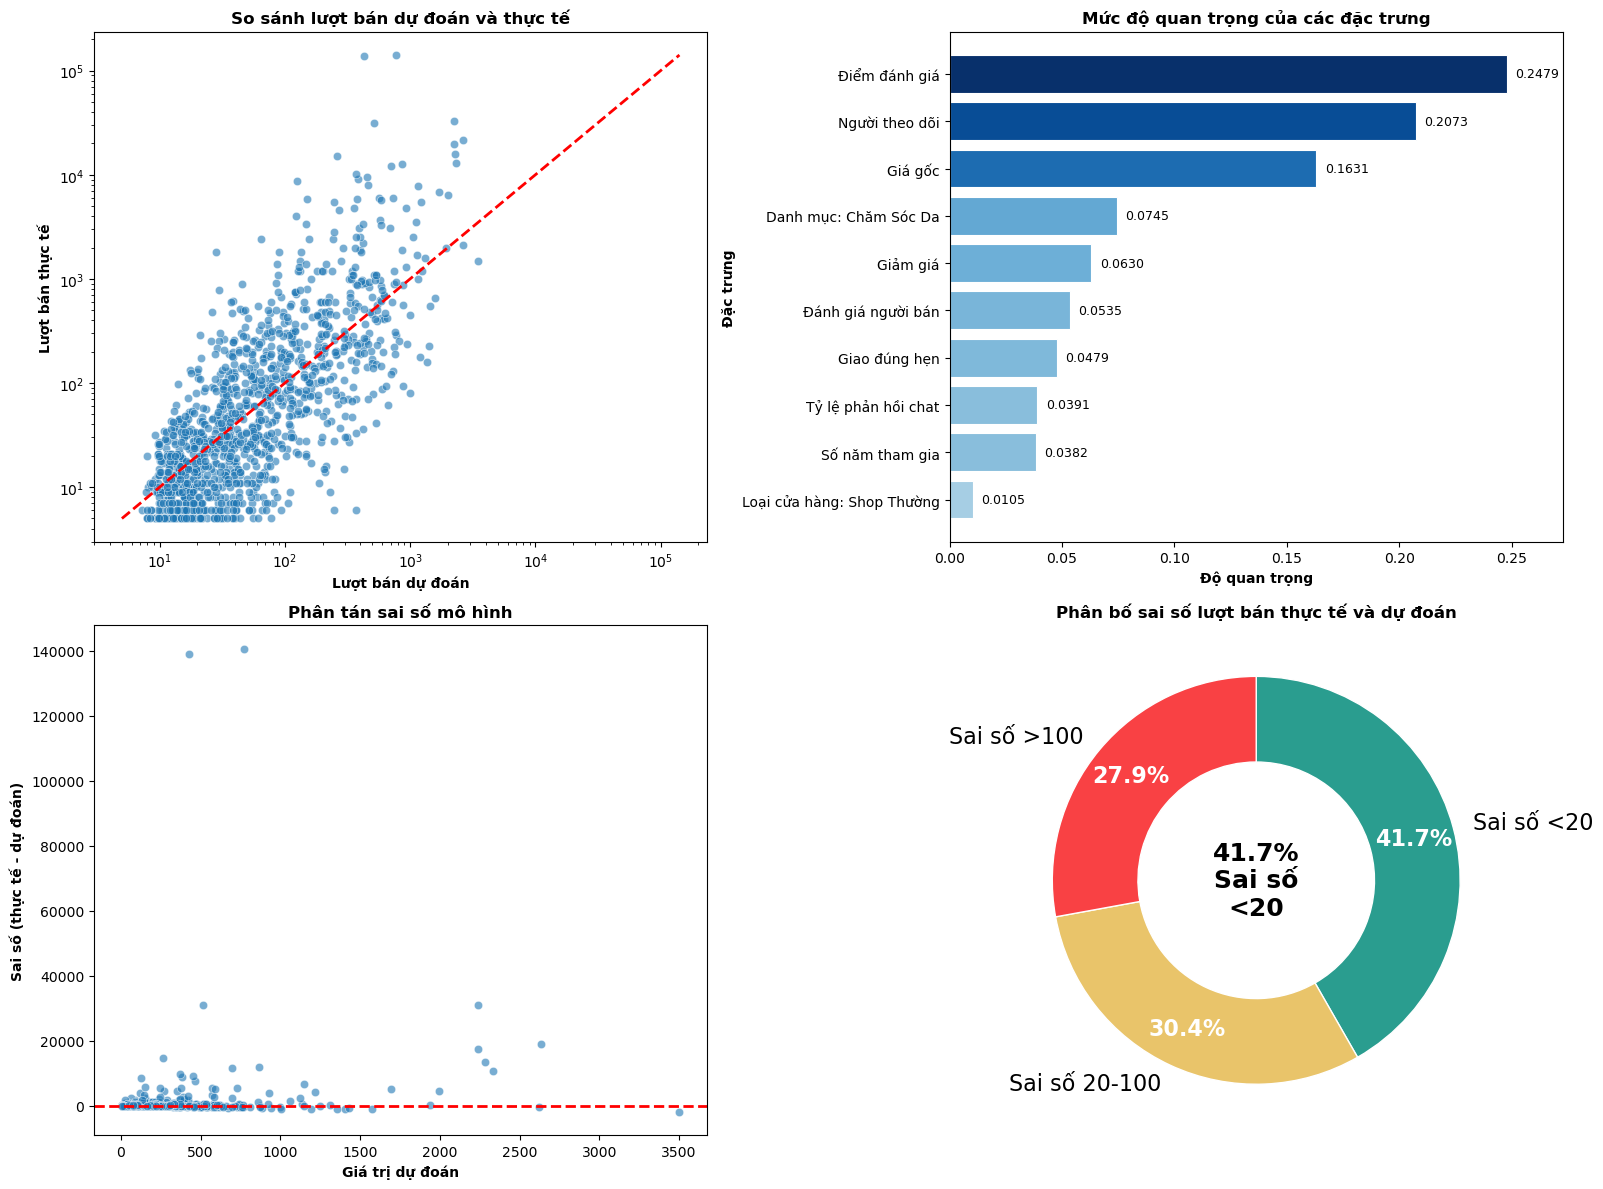

In [145]:
print('=== Kết quả đánh giá mô hình ===')
display(metrics)
print('Bộ biến đã đưa vào mô hình:')
print(feature_cols)
print(f"Mô hình được chọn: {best_model_name}")
print(f"R-squared trên log target: {best_r2_log:.4f}")
print(f"R-squared trên scale gốc: {best_r2_original:.4f}")
if best_r2_log >= 0.60:
    print('Đạt ngưỡng M (R-squared >= 0.60) trên log target.')
else:
    print('Chưa đạt ngưỡng M (R-squared >= 0.60), cần bổ sung đặc trưng/mô hình.')

# 4 bieu do voi bo cuc 2x2 theo yeu cau
residuals_raw = y_test - best_pred
x_pred_safe = np.clip(best_pred, 1e-9, None)
y_true_safe = np.clip(y_test, 1e-9, None)

# Sai so tuyet doi de ve donut
abs_error = np.abs(y_test - best_pred)
err_lt_20_mask = abs_error < 20
err_20_100_mask = (abs_error >= 20) & (abs_error <= 100)
err_gt_100_mask = abs_error > 100

pct_lt_20 = float(err_lt_20_mask.mean() * 100)
pct_20_100 = float(err_20_100_mask.mean() * 100)
pct_gt_100 = float(err_gt_100_mask.mean() * 100)

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
ax_actual_pred = axes[0, 0]
ax_importance = axes[0, 1]
ax_residual_raw = axes[1, 0]
ax_error_donut = axes[1, 1]

# (Goc trai tren) Actual vs Predicted
sns.scatterplot(x=x_pred_safe, y=y_true_safe, alpha=0.6, ax=ax_actual_pred)
min_val = max(min(y_test.min(), best_pred.min()), 1e-6)
max_val = max(y_test.max(), best_pred.max())
ax_actual_pred.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2)
ax_actual_pred.set_xscale('log')
ax_actual_pred.set_yscale('log')
ax_actual_pred.set_xlabel('Lượt bán dự đoán', fontweight='bold')
ax_actual_pred.set_ylabel('Lượt bán thực tế', fontweight='bold')
ax_actual_pred.set_title('So sánh lượt bán dự đoán và thực tế', fontweight='bold')

# (Goc phai tren) Feature Importance
if hasattr(rf_model.named_steps['model'], 'feature_importances_'):
    rf_feature_names = rf_model.named_steps['preprocess'].get_feature_names_out()
    rf_importances = rf_model.named_steps['model'].feature_importances_
    rf_importance_df = pd.DataFrame({
        'Feature': rf_feature_names,
        'Importance': rf_importances
    }).sort_values('Importance', ascending=False)

    top_n = min(10, rf_importance_df.shape[0])
    top_features = rf_importance_df.head(top_n).sort_values('Importance', ascending=True)

    feature_label_map = {
        'Gia_goc': 'Giá gốc',
        'Giam_gia': 'Giảm giá',
        'Diem_danh_gia': 'Điểm đánh giá',
        'Followers': 'Người theo dõi',
        'Danh_gia_nguoi_ban': 'Đánh giá người bán',
        'So_nam_tham_gia': 'Số năm tham gia',
        'Ty_le_phan_hoi_chat': 'Tỷ lệ phản hồi chat',
        'Giao_dung_hen': 'Giao đúng hẹn',
        'Danh_muc': 'Danh mục',
        'Loai_cua_hang': 'Loại cửa hàng'
    }

    def prettify_feature_name(raw_name):
        cleaned = raw_name.replace('num__', '').replace('cat__', '')
        if cleaned.startswith('Danh_muc_'):
            value = cleaned[len('Danh_muc_'):].replace('_', ' ')
            return f'Danh mục: {value}'
        if cleaned.startswith('Loai_cua_hang_'):
            value = cleaned[len('Loai_cua_hang_'):].replace('_', ' ')
            return f'Loại cửa hàng: {value}'
        return feature_label_map.get(cleaned, cleaned.replace('_', ' '))

    top_features['Feature_clean'] = top_features['Feature'].map(prettify_feature_name)

    min_imp = top_features['Importance'].min()
    max_imp = top_features['Importance'].max()
    denom = max(max_imp - min_imp, 1e-12)
    norm_vals = (top_features['Importance'] - min_imp) / denom
    bar_colors = [plt.cm.Blues(0.35 + 0.65 * v) for v in norm_vals]

    ax_importance.barh(
        y=top_features['Feature_clean'],
        width=top_features['Importance'],
        color=bar_colors,
        edgecolor='white',
        linewidth=0.8
    )
    ax_importance.set_xlabel('Độ quan trọng', fontweight='bold')
    ax_importance.set_ylabel('Đặc trưng', fontweight='bold')
    ax_importance.set_title('Mức độ quan trọng của các đặc trưng', fontweight='bold')

    # Tang gioi han truc X de nhan gia tri khong bi tran khoi khung
    x_max = float(top_features['Importance'].max())
    ax_importance.set_xlim(0, x_max * 1.1)

    label_offset = x_max * 0.015
    for i, value in enumerate(top_features['Importance']):
        text_x = min(value + label_offset, x_max * 1.18)
        ax_importance.text(text_x, i, f'{value:.4f}', va='center', ha='left', fontsize=9)
else:
    ax_importance.text(
        0.5, 0.5,
        'Không có feature importance cho mô hình hiện tại.',
        ha='center', va='center', fontsize=12
    )
    ax_importance.set_axis_off()

# (Goc trai duoi) Residual raw
sns.scatterplot(x=x_pred_safe, y=residuals_raw, alpha=0.6, ax=ax_residual_raw)
ax_residual_raw.axhline(0, color='red', linestyle='--', linewidth=2)
ax_residual_raw.set_xlabel('Giá trị dự đoán', fontweight='bold')
ax_residual_raw.set_ylabel('Sai số (thực tế - dự đoán)', fontweight='bold')
ax_residual_raw.set_title('Phân tán sai số mô hình', fontweight='bold')

# (Goc phai duoi) Donut ty le sai so tuyet doi theo 3 moc
donut_sizes = [pct_lt_20, pct_20_100, pct_gt_100]
donut_labels = ['Sai số <20', 'Sai số 20-100', 'Sai số >100']
donut_colors = ['#2a9d8f', '#e9c46a', '#f94144']

wedges, texts, autotexts = ax_error_donut.pie(
    donut_sizes,
    labels=donut_labels,
    colors=donut_colors,
    startangle=90,
    counterclock=False,
    wedgeprops={'width': 0.42, 'edgecolor': 'white'},
    autopct='%1.1f%%',
    pctdistance=0.80,
    textprops={'fontsize': 16}
 )
for t in autotexts:
    t.set_color('white')
    t.set_fontweight('bold')

ax_error_donut.text(
    0, 0,
    f'{pct_lt_20:.1f}%\nSai số\n<20',
    ha='center', va='center', fontsize=18, fontweight='bold'
 )
ax_error_donut.set_title('Phân bố sai số lượt bán thực tế và dự đoán', fontweight='bold')

# Dong chu dien giai cho hoi dong
print(f"Tỷ lệ sai số <20: {pct_lt_20:.2f}%")
print(f"Tỷ lệ sai số 20-100: {pct_20_100:.2f}%")
print(f"Tỷ lệ sai số >100: {pct_gt_100:.2f}%")

plt.tight_layout()
plt.show()

### Lý do chọn biểu đồ:
>- Nhóm dùng bộ 4 biểu đồ để kiểm định mô hình từ nhiều góc nhìn thay vì chỉ nhìn một chỉ số tổng hợp. 
>- Biểu đồ Scatter (góc trái trên) cho thấy mức độ bám giữa dự đoán và thực tế trên toàn miền dữ liệu; 
>- Bar chart giải thích biến nào ảnh hưởng mạnh đến dự đoán; 
>- Biểu đồ Scatter (góc trái dưới) giúp nhận diện độ lớn sai số theo đơn vị lượt bán và phát hiện các ngoại lệ lớn; 
>- Biểu đồ Donut chuyển sai số thành các ngưỡng (<20, 20-100, >100) để dễ truyền đạt.
>
### Nhận xét từ biểu đồ: 
>- Mô hình đã học được xu hướng chung khi phần lớn điểm dự đoán đi theo đường chéo trên biểu đồ so sánh thực tế - dự đoán, nhưng vẫn còn cụm điểm lệch xa ở một số vùng dữ liệu. 
>- Động lực thúc đẩy doanh số: Biểu đồ Mức độ quan trọng chỉ ra doanh thu bị chi phối bởi "Tam giác vàng" gồm: Chất lượng (Điểm đánh giá ~ 24.8%), Quy mô uy tín (Người theo dõi ~ 20.7%) và Định vị phân khúc (Giá gốc ~ 16.3%). Khuyến mãi (Giảm giá) đóng vai trò rất mờ nhạt (6.3%), chứng tỏ khách hàng mua vì niềm tin hơn là ham rẻ. 
>- Bản chất sai số: Mô hình nắm bắt khá tốt xu hướng chung ($R^2$ trên log target đạt 0.5626) nhưng bị đánh gục trên thang đo gốc ($R^2$ = 0.0131) do biểu đồ phần dư (góc trái dưới) xuất hiện các siêu phẩm lệch tới 140.000 đơn. Tuy nhiên, biểu đồ Donut chỉ rõ các ngoại lệ này chỉ chiếm một tỷ lệ thiểu số. Trên thực tế, có tới 72.13% danh mục sản phẩm được mô hình dự đoán với mức chênh lệch kiểm soát tốt dưới 100 đơn/tháng (trong đó 41.7% lệch chưa tới 20 đơn/tháng).
>
### Kết luận: 
>Mô hình hiện tại phù hợp cho mục tiêu hỗ trợ phân tích xu hướng lượt bán và so sánh tương đối giữa các nhóm sản phẩm/shop. Tuy nhiên, nếu dùng cho tác vụ dự báo vận hành có yêu cầu chính xác cao, nhóm cần tiếp tục tối ưu để giảm tỷ lệ sai số lớn (ví dụ bổ sung biến thời gian, đặc trưng hành vi, và kiểm định theo thời gian). Nhìn tổng thể, kết quả đã có giá trị thực tiễn và là nền tảng tốt cho vòng cải tiến tiếp theo của bài toán dự đoán.

## Mô tả kịch bản What-if
- Mục tiêu: Ước lượng mức thay đổi lượt bán toàn hệ thống nếu tháng tới tăng mức giảm giá thêm 5 điểm phần trăm cho toàn bộ sản phẩm.
- Cách mô phỏng: Giữ nguyên các đặc trưng khác, chỉ điều chỉnh biến `Giam_gia` theo công thức `Giam_gia_moi = Giam_gia_hien_tai + 0.05`, và giới hạn trần ở 99% để tránh giá trị không hợp lệ.
- Đầu ra phân tích:
  - Dự báo tổng lượt bán ở trạng thái hiện tại.
  - Dự báo tổng lượt bán ở kịch bản tăng giảm giá +5%.
  - Chênh lệch tuyệt đối và tỷ lệ thay đổi (%).
  - Bảng phân rã kết quả theo từng loại cửa hàng (LazMall, Shop Thường).
- Ý nghĩa sử dụng: Giúp trả lời nhanh câu hỏi “Nếu điều chỉnh chính sách khuyến mãi đồng loạt thì doanh số dự kiến tăng hay giảm bao nhiêu”, từ đó hỗ trợ quyết định chiến lược giá trước khi triển khai thực tế.

In [146]:
# Du bao chien luoc (What-if): gia su thang sau tang giam gia them 5%
pred_baseline_log = best_model.predict(X)
pred_baseline = np.expm1(pred_baseline_log).clip(min=0)

X_scenario = X.copy()
if 'Giam_gia' not in X_scenario.columns:
    raise ValueError("Khong tim thay cot 'Giam_gia' trong tap du lieu mo phong.")
X_scenario['Giam_gia'] = (X_scenario['Giam_gia'] + 0.05).clip(upper=0.99)

pred_scenario_log = best_model.predict(X_scenario)
pred_scenario = np.expm1(pred_scenario_log).clip(min=0)

forecast_df = ml_df.copy()
# Xoa cot cu neu ton tai de tranh nham lan
if 'Du_bao_kich_ban_tang_giam_5' in forecast_df.columns:
    forecast_df = forecast_df.drop(columns=['Du_bao_kich_ban_tang_giam_5'])

forecast_df['Dự báo hiện tại'] = pred_baseline
forecast_df['Dự báo kịch bản tăng giảm giá +5%'] = pred_scenario

total_baseline_units = forecast_df['Dự báo hiện tại'].sum()
total_scenario_units = forecast_df['Dự báo kịch bản tăng giảm giá +5%'].sum()
delta_units = total_scenario_units - total_baseline_units
delta_pct = delta_units / max(total_baseline_units, 1) * 100

summary_forecast = pd.DataFrame({
    'Chỉ số': [
        'Tổng dự đoán hệ thống hiện tại',
        'Tổng dự đoán kịch bản tăng giảm giá +5%',
        'Chênh lệch tuyệt đối (kịch bản - hiện tại)',
        'Tỷ lệ thay đổi so với hệ thống hiện tại (%)'
    ],
    'Giá trị': [
        f"{total_baseline_units:,.0f}",
        f"{total_scenario_units:,.0f}",
        f"{delta_units:,.0f}",
        f"{delta_pct:,.2f}%"
    ]
})

print('=== Tổng hợp dự báo chiến lược ===')
display(summary_forecast)

forecast_by_shop_type = (
    forecast_df.groupby('Loai_cua_hang')[['Dự báo hiện tại', 'Dự báo kịch bản tăng giảm giá +5%']]
    .sum()
    .reset_index()
    .rename(columns={'Loai_cua_hang': 'Loại cửa hàng'})
)
forecast_by_shop_type['Chênh lệch'] = (
    forecast_by_shop_type['Dự báo kịch bản tăng giảm giá +5%'] - forecast_by_shop_type['Dự báo hiện tại']
 )
forecast_by_shop_type['Tỷ lệ thay đổi (%)'] = (
    forecast_by_shop_type['Chênh lệch'] / forecast_by_shop_type['Dự báo hiện tại'].clip(lower=1) * 100
 )

forecast_by_shop_type['Dự báo hiện tại'] = forecast_by_shop_type['Dự báo hiện tại'].map(lambda x: f"{x:,.0f}")
forecast_by_shop_type['Dự báo kịch bản tăng giảm giá +5%'] = forecast_by_shop_type['Dự báo kịch bản tăng giảm giá +5%'].map(lambda x: f"{x:,.0f}")
forecast_by_shop_type['Chênh lệch'] = forecast_by_shop_type['Chênh lệch'].map(lambda x: f"{x:,.0f}")
forecast_by_shop_type['Tỷ lệ thay đổi (%)'] = forecast_by_shop_type['Tỷ lệ thay đổi (%)'].map(lambda x: f"{x:,.2f}%")

print('=== Dự báo chiến lược theo loại cửa hàng ===')
display(forecast_by_shop_type)

=== Tổng hợp dự báo chiến lược ===


,Chỉ số,Giá trị
0,Tổng dự đoán hệ thống hiện tại,"804,384"
1,Tổng dự đoán kịch bản tăng giảm giá +5%,"802,747"
2,Chênh lệch tuyệt đối (kịch bản - hiện tại),"-1,636"
3,Tỷ lệ thay đổi so với hệ thống hiện tại (%),-0.20%


=== Dự báo chiến lược theo loại cửa hàng ===


,Loại cửa hàng,Dự báo hiện tại,Dự báo kịch bản tăng giảm giá +5%,Chênh lệch,Tỷ lệ thay đổi (%)
0,LazMall,"196,818","196,473",-345,-0.18%
1,Shop Thường,"607,565","606,275","-1,291",-0.21%


### Kết luận kịch bản What-if (+5% giảm giá)
>- Khi tăng thêm 5 điểm phần trăm mức giảm giá trên toàn bộ sản phẩm, mô hình cho thấy tổng lượt bán dự báo của hệ thống thay đổi ở mức nhỏ, không tạo bứt phá rõ rệt ở quy mô toàn sàn.
>- Kết quả theo từng loại cửa hàng cho thấy tác động không đồng đều: mỗi nhóm cửa hàng phản ứng khác nhau với cùng một chính sách giá, do khác biệt về tệp khách hàng, mức độ uy tín và khả năng chuyển đổi.
>- Hàm ý quản trị: không nên áp dụng một mức tăng giảm giá đồng loạt cho tất cả gian hàng. Nên triển khai theo hướng phân nhóm (danh mục, loại cửa hàng, mức độ nhạy cảm giá) để tối ưu hiệu quả.